
--- RANDOM FOREST METRİK TABLOSU ---
            Accuracy  Precision    Recall  F1-score
Train       0.919626   0.902129  0.939119  0.915701
Validation  0.894089   0.873870  0.911392  0.887270
Test        0.896305   0.868662  0.914543  0.884632


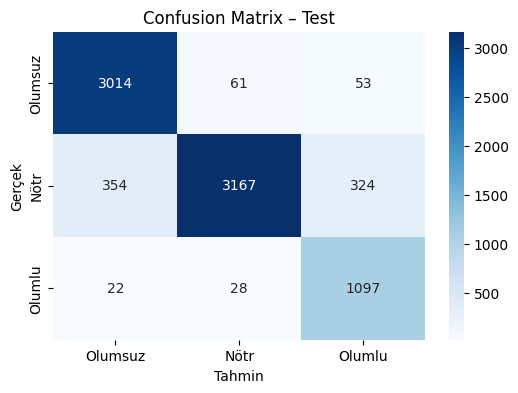

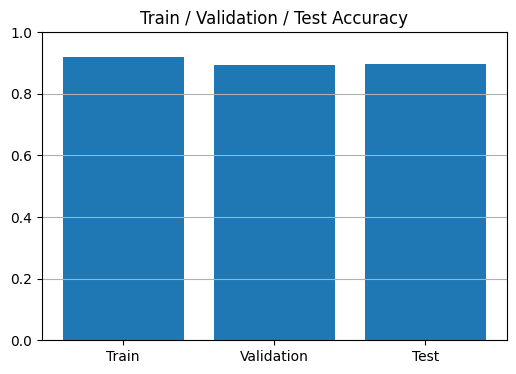

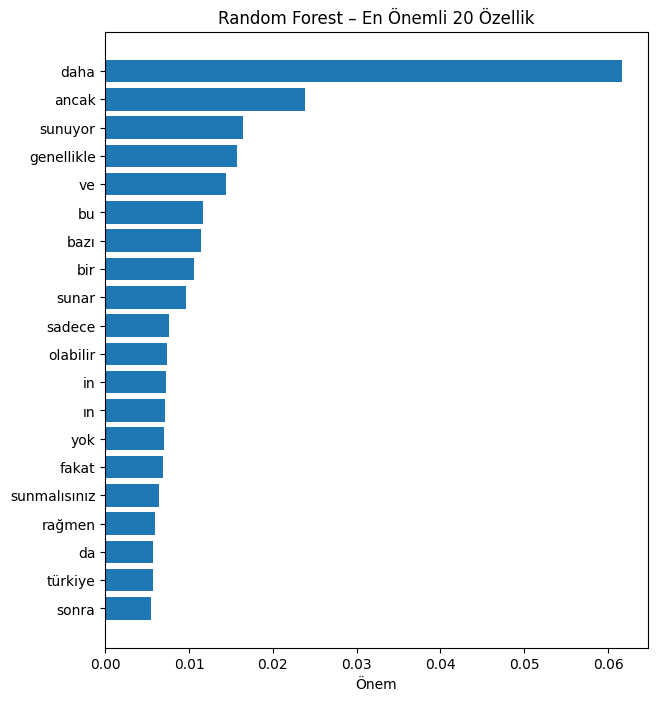

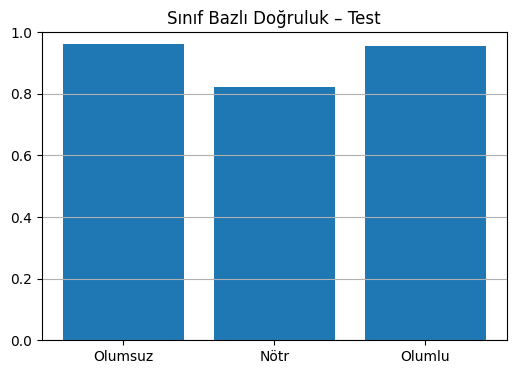

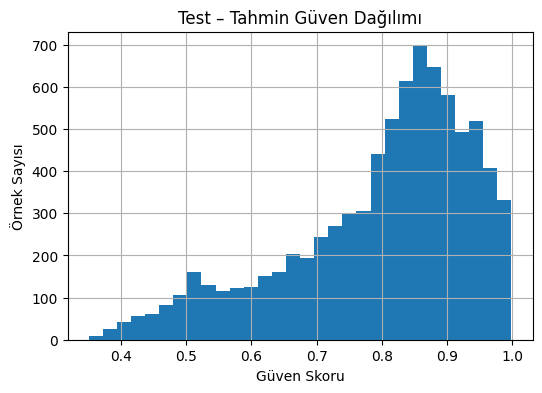

In [1]:
# ===================================================
# 0) KÜTÜPHANELER
# ===================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# ===================================================
# 1) VERİYİ YÜKLE (SADECE CSV)
# ===================================================
df = pd.read_csv("Turkish-Review-Sentiment-Data.csv")
df.columns = [c.lower() for c in df.columns]

TEXT_COL = "review"
LABEL_COL = "sentiment"

# ===================================================
# 2) LABEL MAP
# ===================================================
label_map = {
    "olumsuz": 0, "negatif": 0,
    "nötr": 1, "notr": 1, "neutral": 1,
    "olumlu": 2, "pozitif": 2, "positive": 2
}

df[LABEL_COL] = (
    df[LABEL_COL]
    .astype(str)
    .str.lower()
    .map(label_map)
    .fillna(1)
    .astype(int)
)

# ===================================================
# 3) METİN TEMİZLEME
# ===================================================
def clean_text(x):
    if pd.isna(x):
        return ""
    return str(x).lower().replace("\n", " ").strip()

df[TEXT_COL] = df[TEXT_COL].apply(clean_text)

# ===================================================
# 4) 70 TRAIN / 20 TEST / 10 VALIDATION
# ===================================================
X = df[TEXT_COL]
y = df[LABEL_COL]

# %70 Train
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

# %20 Test / %10 Validation
X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=1/3, stratify=y_temp, random_state=42
)

# ===================================================
# 5) TF-IDF
# ===================================================
vectorizer = TfidfVectorizer(
    max_features=25000,
    ngram_range=(1, 2),
    min_df=3
)

X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec   = vectorizer.transform(X_val)
X_test_vec  = vectorizer.transform(X_test)

# ===================================================
# 6) RANDOM FOREST (SADECE TRAIN İLE EĞİTİLİR)
# ===================================================
rf = RandomForestClassifier(
    n_estimators=400,
    min_samples_split=4,
    min_samples_leaf=2,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)

rf.fit(X_train_vec, y_train)

# ===================================================
# 7) TAHMİNLER
# ===================================================
train_pred = rf.predict(X_train_vec)
val_pred   = rf.predict(X_val_vec)
test_pred  = rf.predict(X_test_vec)

# ===================================================
# 8) METRİK FONKSİYONU
# ===================================================
def calc_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro"
    )
    return acc, p, r, f1

# ===================================================
# 9) METRİK TABLOSU
# ===================================================
metrics_df = pd.DataFrame({
    "Accuracy": [
        calc_metrics(y_train, train_pred)[0],
        calc_metrics(y_val, val_pred)[0],
        calc_metrics(y_test, test_pred)[0]
    ],
    "Precision": [
        calc_metrics(y_train, train_pred)[1],
        calc_metrics(y_val, val_pred)[1],
        calc_metrics(y_test, test_pred)[1]
    ],
    "Recall": [
        calc_metrics(y_train, train_pred)[2],
        calc_metrics(y_val, val_pred)[2],
        calc_metrics(y_test, test_pred)[2]
    ],
    "F1-score": [
        calc_metrics(y_train, train_pred)[3],
        calc_metrics(y_val, val_pred)[3],
        calc_metrics(y_test, test_pred)[3]
    ]
}, index=["Train", "Validation", "Test"])

print("\n--- RANDOM FOREST METRİK TABLOSU ---")
print(metrics_df)

# ===================================================
# 10) GRAFİKLER
# ===================================================
class_names = ["Olumsuz", "Nötr", "Olumlu"]

# --- Confusion Matrix (Test)
plt.figure(figsize=(6,4))
sns.heatmap(
    confusion_matrix(y_test, test_pred),
    annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Confusion Matrix – Test")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.show()

# --- Accuracy Bar
plt.figure(figsize=(6,4))
plt.bar(metrics_df.index, metrics_df["Accuracy"])
plt.title("Train / Validation / Test Accuracy")
plt.ylim(0,1)
plt.grid(axis="y")
plt.show()

# --- Feature Importance (Top 20)
importances = rf.feature_importances_
indices = np.argsort(importances)[-20:]
feature_names = np.array(vectorizer.get_feature_names_out())

plt.figure(figsize=(7,8))
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), feature_names[indices])
plt.title("Random Forest – En Önemli 20 Özellik")
plt.xlabel("Önem")
plt.show()

# --- Sınıf Bazlı Doğruluk (Test)
class_acc = []
for cls in [0,1,2]:
    idx = np.where(y_test.values == cls)[0]
    class_acc.append(
        accuracy_score(y_test.values[idx], test_pred[idx])
    )

plt.figure(figsize=(6,4))
plt.bar(class_names, class_acc)
plt.title("Sınıf Bazlı Doğruluk – Test")
plt.ylim(0,1)
plt.grid(axis="y")
plt.show()

# --- Güven Dağılımı
probs = rf.predict_proba(X_test_vec)
confidence = np.max(probs, axis=1)

plt.figure(figsize=(6,4))
plt.hist(confidence, bins=30)
plt.title("Test – Tahmin Güven Dağılımı")
plt.xlabel("Güven Skoru")
plt.ylabel("Örnek Sayısı")
plt.grid(True)
plt.show()
